In [ ]:
import os
from pathlib import Path

PROJECT_DIR = Path("E:/Quera ML/Project 2")
CACHE_DIR = PROJECT_DIR / "hf_cache"

os.environ["HF_HUB_CACHE"] = str(CACHE_DIR / "hub")
os.environ["HF_DATASETS_CACHE"] = str(CACHE_DIR / "datasets")
os.environ["HF_XET_CACHE"] = str(CACHE_DIR / "xet")

print("Cache location:", CACHE_DIR)

In [ ]:
from huggingface_hub import login, whoami

login()

print(whoami()["name"])


In [3]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="nexar-ai/nexar_collision_prediction",
    repo_type="dataset",
    allow_patterns=[
        "train/positive/metadata.csv",
        "train/negative/metadata.csv"
    ],
    local_dir="data/raw"
)

print(dataset_path)


c:\Users\User\miniconda3\envs\quera\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 124.98it/s]

E:\Quera ML\Project 2\data\raw


In [4]:
from datasets import load_dataset
import torchcodec
import pandas as pd
from decord import VideoReader, cpu
from pathlib import Path
import matplotlib.pyplot as plt 
from datasets import load_dataset, Video
from huggingface_hub import hf_hub_download
import json
import shutil
import os
import random
from getpass import getpass
from huggingface_hub import HfApi, hf_hub_download, login
import numpy as np
import cv2
from tqdm.auto import tqdm



In [5]:
negative = pd.read_csv("n-metadata.csv")
positive = pd.read_csv("p-metadata.csv")

df = pd.concat([negative, positive], ignore_index=True)
df["target"] = df["time_of_event"].notna().astype(int)

print(df.shape)
print(df["target"].value_counts())
print(df.isna().sum())


(1500, 8)
target
0    750
1    750
Name: count, dtype: int64
file_name              0
time_of_event        750
time_of_alert        750
light_conditions       0
weather                2
scene                  0
time_to_accident    1500
target                 0
dtype: int64


In [6]:
df

,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident,target
0,01924.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN,0
1,01429.mp4,NaN,NaN,Normal,Rain,Urban,NaN,0
2,01904.mp4,NaN,NaN,Normal,Cloudy,Urban,NaN,0
3,01486.mp4,NaN,NaN,Normal,Clear,Urban,NaN,0
4,01171.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN,0
...,...,...,...,...,...,...,...,...
1495,00500.mp4,19.933,18.633,Normal,Clear,Urban,NaN,1
1496,00519.mp4,19.567,19.033,Normal,Clear,Urban,NaN,1
1497,00262.mp4,17.900,13.933,Normal,Clear,Highway,NaN,1
1498,00391.mp4,19.867,19.267,Normal,Clear,Urban,NaN,1


In [7]:
def plot_distribution(df, column):
    counts = pd.crosstab(df[column].fillna("Missing"), df["target"])

    order = counts.sum(axis=1).sort_values(ascending=False).index
    percentages = pd.crosstab(df[column].fillna("Missing"), df["target"], normalize="columns") * 100

    percentages = percentages.loc[order]
    percentages = percentages[[0, 1]]

    percentages.columns = [
        "Negative (0)",
        "Positive (1)"
    ]

    ax = percentages.plot(kind="bar", figsize=(10, 5), width=0.8)

    ax.set_title(f"{column} Distribution by Class")
    ax.set_xlabel(column)
    ax.set_ylabel("Percentage within each class (%)")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


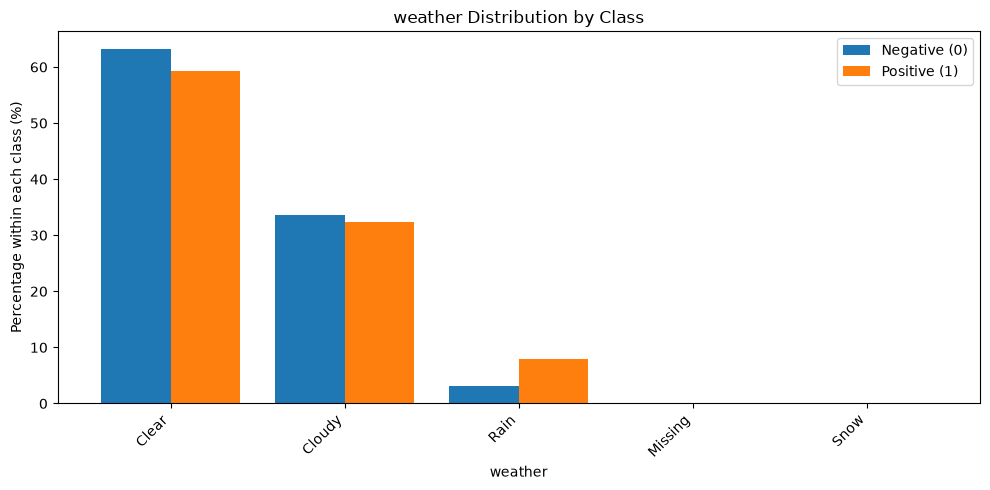

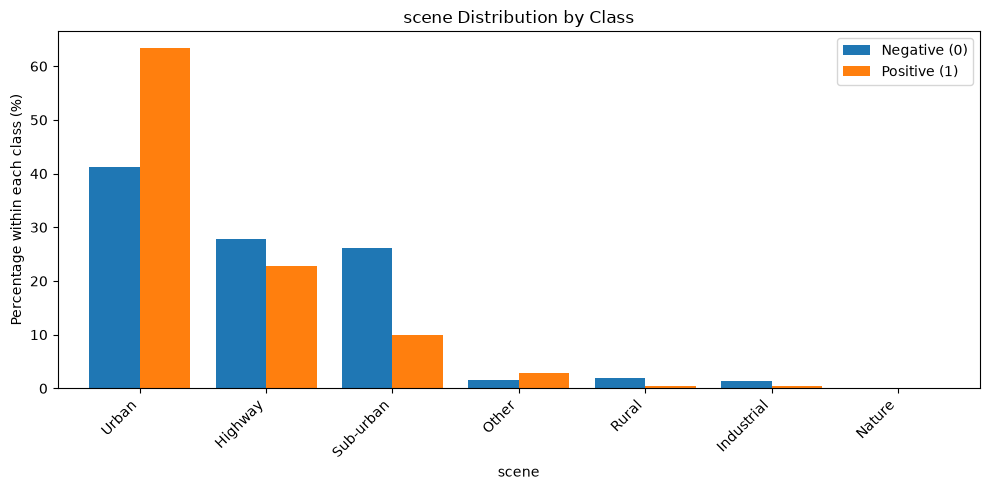

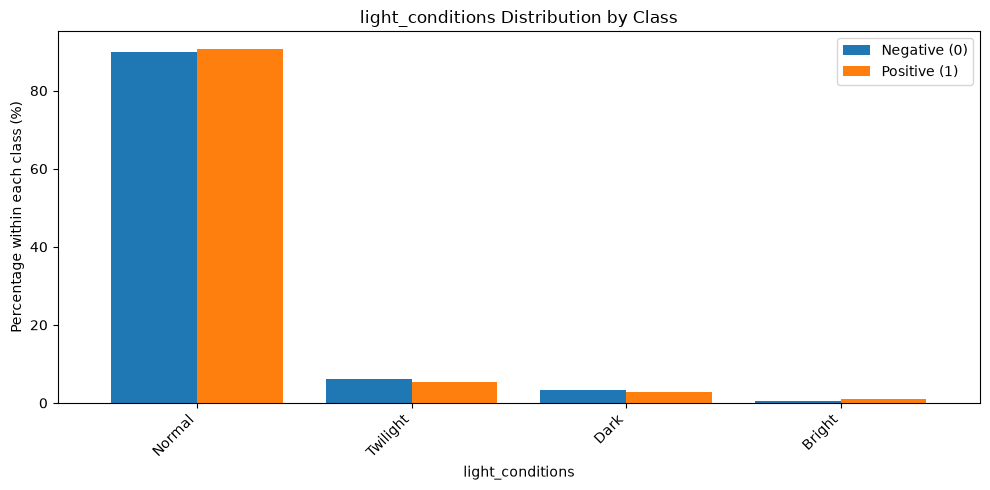

In [8]:
plot_distribution(df, "weather")
plot_distribution(df, "scene")
plot_distribution(df, "light_conditions")

In [9]:
os.environ["KERAS_BACKEND"] = "torch"

import keras
import torch

print("Keras version:", keras.__version__)
print("Keras backend:", keras.backend.backend())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Keras version: 3.15.1
Keras backend: torch
PyTorch version: 2.15.0+cpu
CUDA available: False


In [10]:
##### code for downloading the data set / if you have the data already no need for this cell 
REPO_ID = "nexar-ai/nexar_collision_prediction"
LIMIT = 1500

PROJECT_DIR = Path("E:/Quera ML/Project 2")

OUT_DIR = PROJECT_DIR / "nexar_data"
VIDEO_DIR = OUT_DIR / "videos"
META_DIR = OUT_DIR / "metadata"

VIDEO_DIR.mkdir(parents=True, exist_ok=True)
META_DIR.mkdir(parents=True, exist_ok=True)

dataset = load_dataset(
    REPO_ID,
    split="train",
    streaming=True
).cast_column("video", Video(decode=False))

records = []

for index, example in enumerate(dataset):
    if index >= LIMIT:
        break

    video_id = f"video_{index:06d}"
    
    video_path = VIDEO_DIR / f"{video_id}.mp4"
    metadata_path = META_DIR / f"{video_id}.json"

    if video_path.exists() and metadata_path.exists():
        with open(metadata_path, encoding="utf-8") as f:
            records.append(json.load(f))

        print(f"Already downloaded: {video_id}")
        continue

    video_info = example["video"]
    source_path = video_info.get("path")
    video_bytes = video_info.get("bytes")

    # Download the exact video belonging to this example
    if video_bytes is not None:
        suffix = Path(source_path or "video.mp4").suffix or ".mp4"
        video_path = VIDEO_DIR / f"{video_id}{suffix}"
        video_path.write_bytes(video_bytes)

    elif source_path and source_path.startswith("hf://"):
        # Remove hf://datasets/ and the repo revision from the URL
        # to get the repository-relative path.
        relative_path = source_path.split("/", 4)[-1]
        relative_path = relative_path.split("/", 1)[-1]

        # Expected path: train/negative/01924.mp4
        if "@" in relative_path:
            relative_path = relative_path.split("/", 1)[-1]


        downloaded_path = Path(
            hf_hub_download(
                repo_id=REPO_ID,
                repo_type="dataset",
                filename=relative_path,
                local_dir=str(VIDEO_DIR)
            )
        )

        suffix = downloaded_path.suffix or ".mp4"
        video_path = VIDEO_DIR / f"{video_id}{suffix}"
        downloaded_path.replace(video_path)


    else:
        raise RuntimeError(
            f"Cannot download video for index {index}: {source_path}"
        )

    # Save metadata from the SAME example
    metadata = {
        key: value
        for key, value in example.items()
        if key != "video"
    }
    metadata.update({
        "dataset_index": index,
        "video_id": video_id,
        "video_file": str(video_path.resolve()),
        "source_video_path": source_path,
    })

    with open(
        META_DIR / f"{video_id}.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(metadata, f, indent=2, ensure_ascii=False, default=str)

    records.append(metadata)
    print(f"Downloaded {index + 1}/{LIMIT}: {video_id}, label={metadata.get('label')}")

pd.DataFrame(records).to_csv(OUT_DIR / "metadata.csv", index=False)

print("\nVideos downloaded:", len(records))
print("Output:", OUT_DIR.resolve())

c:\Users\User\miniconda3\envs\quera\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in E:\Quera ML\Project 2\hf_cache\hub\datasets--nexar-ai--nexar_collision_prediction. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Already downloaded: video_000000
Already downloaded: video_000001
Already downloaded: video_000002
Already downloaded: video_000003
Already downloaded: video_000004
Already downloaded: video_000005
Already downloaded: video_000006
Already downloaded: video_000007
Already downloaded: video_000008
Already downloaded: video_000009
Already downloaded: video_000010
Already downloaded: video_000011
Already downloaded: video_000012
Already downloaded: video_000013
Already downloaded: video_000014
Already downloaded: video_000015
Already downloaded: video_000016
Already downloaded: video_000017
Already downloaded: video_000018
Already downloaded: video_000019
Already downloaded: video_000020
Already downloaded: video_000021
Already downloaded: video_000022
Already downloaded: video_000023
Already downloaded: video_000024
Already downloaded: video_000025
Already downloaded: video_000026
Already downloaded: video_000027
Already downloaded: video_000028
Already downloaded: video_000029
Already do

'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting HEAD https://huggingface.co/datasets/nexar-ai/nexar_collision_prediction/resolve/main/train/negative/01344.mp4
Retrying in 1s [Retry 1/5].


Downloaded 467/1500: video_000466, label=None
Downloaded 468/1500: video_000467, label=None
Downloaded 469/1500: video_000468, label=None
Downloaded 470/1500: video_000469, label=None
Downloaded 471/1500: video_000470, label=None
Downloaded 472/1500: video_000471, label=None
Downloaded 473/1500: video_000472, label=None
Downloaded 474/1500: video_000473, label=None
Downloaded 475/1500: video_000474, label=None
Downloaded 476/1500: video_000475, label=None
Downloaded 477/1500: video_000476, label=None
Downloaded 478/1500: video_000477, label=None
Downloaded 479/1500: video_000478, label=None
Downloaded 480/1500: video_000479, label=None
Downloaded 481/1500: video_000480, label=None
Downloaded 482/1500: video_000481, label=None
Downloaded 483/1500: video_000482, label=None
Downloaded 484/1500: video_000483, label=None
Downloaded 485/1500: video_000484, label=None
Downloaded 486/1500: video_000485, label=None
Downloaded 487/1500: video_000486, label=None
Downloaded 488/1500: video_000487,

'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting HEAD https://huggingface.co/datasets/nexar-ai/nexar_collision_prediction/resolve/main/train/negative/01142.mp4
Retrying in 1s [Retry 1/5].


...

Downloaded 1341/1500: video_001340, label=None
Downloaded 1342/1500: video_001341, label=None
Downloaded 1343/1500: video_001342, label=None
Downloaded 1344/1500: video_001343, label=None
Downloaded 1345/1500: video_001344, label=None
Downloaded 1346/1500: video_001345, label=None
Downloaded 1347/1500: video_001346, label=None
Downloaded 1348/1500: video_001347, label=None
Downloaded 1349/1500: video_001348, label=None
Downloaded 1350/1500: video_001349, label=None
Downloaded 1351/1500: video_001350, label=None
Downloaded 1352/1500: video_001351, label=None
Downloaded 1353/1500: video_001352, label=None
Downloaded 1354/1500: video_001353, label=None
Downloaded 1355/1500: video_001354, label=None
Downloaded 1356/1500: video_001355, label=None
Downloaded 1357/1500: video_001356, label=None
Downloaded 1358/1500: video_001357, label=None
Downloaded 1359/1500: video_001358, label=None
Downloaded 1360/1500: video_001359, label=None
Downloaded 1361/1500: video_001360, label=None
Downloaded 13

'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting HEAD https://huggingface.co/datasets/nexar-ai/nexar_collision_prediction/resolve/main/train/positive/00332.mp4
Retrying in 1s [Retry 1/5].


Downloaded 1452/1500: video_001451, label=None
Downloaded 1453/1500: video_001452, label=None
Downloaded 1454/1500: video_001453, label=None
Downloaded 1455/1500: video_001454, label=None
Downloaded 1456/1500: video_001455, label=None
Downloaded 1457/1500: video_001456, label=None
Downloaded 1458/1500: video_001457, label=None
Downloaded 1459/1500: video_001458, label=None
Downloaded 1460/1500: video_001459, label=None
Downloaded 1461/1500: video_001460, label=None
Downloaded 1462/1500: video_001461, label=None
Downloaded 1463/1500: video_001462, label=None
Downloaded 1464/1500: video_001463, label=None
Downloaded 1465/1500: video_001464, label=None
Downloaded 1466/1500: video_001465, label=None
Downloaded 1467/1500: video_001466, label=None
Downloaded 1468/1500: video_001467, label=None
Downloaded 1469/1500: video_001468, label=None
Downloaded 1470/1500: video_001469, label=None
Downloaded 1471/1500: video_001470, label=None
Downloaded 1472/1500: video_001471, label=None
Downloaded 14

'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting HEAD https://huggingface.co/datasets/nexar-ai/nexar_collision_prediction/resolve/main/train/positive/00406.mp4
Retrying in 1s [Retry 1/5].


Downloaded 1477/1500: video_001476, label=None
Downloaded 1478/1500: video_001477, label=None
Downloaded 1479/1500: video_001478, label=None
Downloaded 1480/1500: video_001479, label=None
Downloaded 1481/1500: video_001480, label=None
Downloaded 1482/1500: video_001481, label=None
Downloaded 1483/1500: video_001482, label=None
Downloaded 1484/1500: video_001483, label=None
Downloaded 1485/1500: video_001484, label=None
Downloaded 1486/1500: video_001485, label=None
Downloaded 1487/1500: video_001486, label=None
Downloaded 1488/1500: video_001487, label=None
Downloaded 1489/1500: video_001488, label=None
Downloaded 1490/1500: video_001489, label=None
Downloaded 1491/1500: video_001490, label=None
Downloaded 1492/1500: video_001491, label=None
Downloaded 1493/1500: video_001492, label=None
Downloaded 1494/1500: video_001493, label=None
Downloaded 1495/1500: video_001494, label=None
Downloaded 1496/1500: video_001495, label=None
Downloaded 1497/1500: video_001496, label=None
Downloaded 14